<a href="https://colab.research.google.com/github/Tejendersingsethi334/Maincraft-/blob/main/Maincraft_Task3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Cell 1 — Import libraries and load the dataset**

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

# Upload train.csv
uploaded = files.upload()

# Load dataset
df = pd.read_csv("train.csv")

# Display first five rows
print("First five rows:")
display(df.head())

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())


Saving train.csv to train (1).csv
First five rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Dataset shape: (891, 12)

Column names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


Explanation: Pandas handles data analysis, Matplotlib and Seaborn create charts, and the upload option lets you select train.csv from your computer.

# Cell 2 — Explore and clean the dataset

In [2]:

# Check missing values before cleaning
print("Missing values before cleaning:")
print(df.isnull().sum())

# Fill missing Age with mean
df["Age"] = df["Age"].fillna(df["Age"].mean())

# Drop irrelevant columns
df = df.drop(columns=["Cabin"], errors="ignore")

# Fill missing Embarked values with the mode
# so port-based analysis can use the available records
if df["Embarked"].isnull().any():
    df["Embarked"] = df["Embarked"].fillna(
        df["Embarked"].mode()[0]
    )

# Create age groups
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 12, 18, 35, 60, np.inf],
    labels=["Child", "Teenager", "Young Adult",
            "Adult", "Senior"],
    include_lowest=True
)

# Calculate family size exactly as specified in the task
df["FamilySize"] = df["SibSp"] + df["Parch"]

# Display cleaned dataset
print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nCleaned dataset:")
display(df.head())


Missing values before cleaning:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Missing values after cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
AgeGroup       0
FamilySize     0
dtype: int64

Cleaned dataset:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,AgeGroup,FamilySize
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,Young Adult,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,Adult,1
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,Young Adult,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,Young Adult,1
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,Young Adult,0


Explanation:
- fillna() replaces missing Age values with the average Age.
- drop() removes the Cabin column.
- AgeGroup categorizes passengers by age.
- FamilySize calculates the number of siblings/spouses plus parents/children aboard. It excludes the passenger themselves, following the task's formula.
- Missing Embarked values are filled with the most frequent port so the port analysis can include those rows.

# Cell 3 — Survival rate by age group

Survival Rate by Age Group (%):


,Survival Rate (%)
AgeGroup,
Child,57.97
Teenager,42.86
Young Adult,35.33
Adult,40.00
Senior,22.73


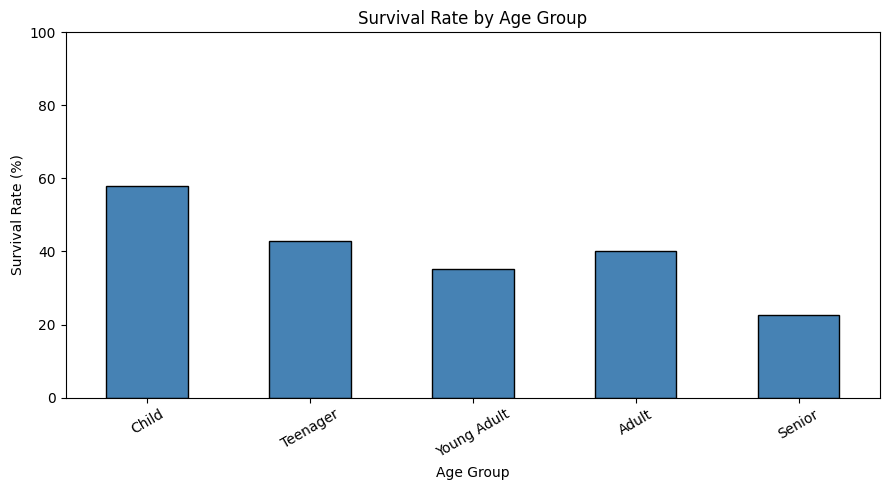

In [3]:

age_survival = (
    df.groupby("AgeGroup", observed=False)["Survived"]
    .mean()
    .mul(100)
    .round(2)
)

print("Survival Rate by Age Group (%):")
display(age_survival.rename("Survival Rate (%)").to_frame())

age_survival.plot(
    kind="bar",
    figsize=(9, 5),
    color="steelblue",
    edgecolor="black"
)

plt.title("Survival Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Survival Rate (%)")
plt.xticks(rotation=30)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


What this tells you: Which age groups had higher and lower survival rates. The values are percentages, not passenger counts.

# Cell 4 — Survival rate by embarkation port

Survival Rate by Embarkation Port (%):


,Survival Rate (%)
Embarked,
Cherbourg,55.36
Queenstown,38.96
Southampton,33.90


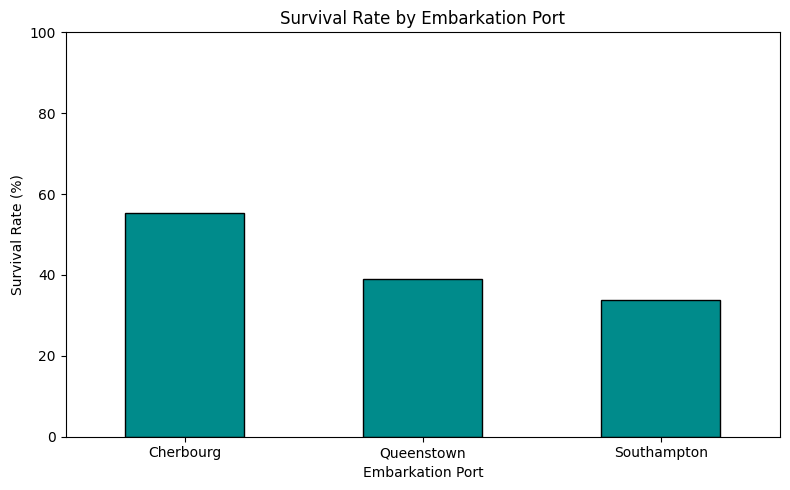

In [4]:

port_names = {
    "C": "Cherbourg",
    "Q": "Queenstown",
    "S": "Southampton"
}

port_survival = (
    df.groupby("Embarked")["Survived"]
    .mean()
    .mul(100)
    .round(2)
)

port_survival.index = port_survival.index.map(
    lambda x: port_names.get(x, x)
)

print("Survival Rate by Embarkation Port (%):")
display(port_survival.rename("Survival Rate (%)").to_frame())

port_survival.plot(
    kind="bar",
    figsize=(8, 5),
    color="darkcyan",
    edgecolor="black"
)

plt.title("Survival Rate by Embarkation Port")
plt.xlabel("Embarkation Port")
plt.ylabel("Survival Rate (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


What this tells you: How survival rates differed between passengers who boarded at Cherbourg, Queenstown, and Southampton. These are associations, not proof that the port caused the difference.

# Cell 5 — Survival rate by family size

Survival by Family Size:


,count,Survival Rate (%)
FamilySize,,
0,537,30.35
1,161,55.28
2,102,57.84
3,29,72.41
4,15,20.00
5,22,13.64
6,12,33.33
7,6,0.00
10,7,0.00


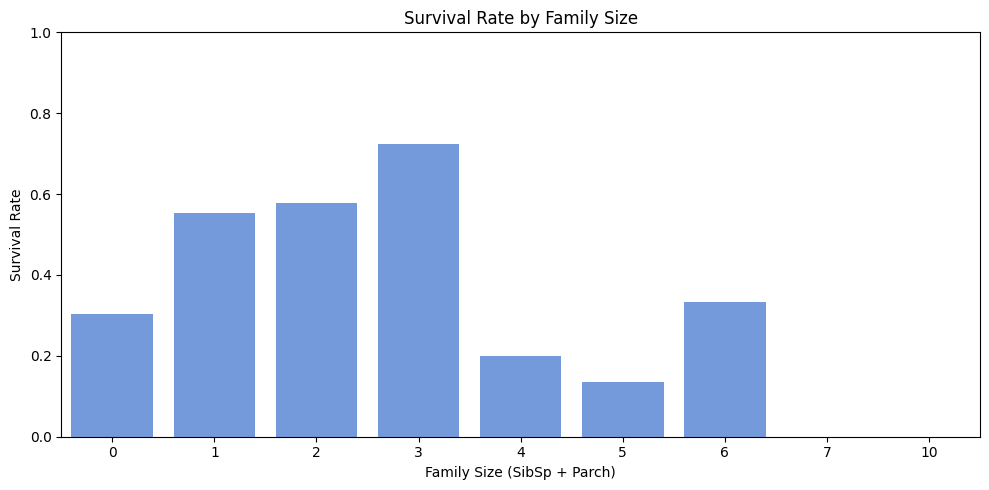

In [5]:

family_survival = (
    df.groupby("FamilySize")["Survived"]
    .agg(["mean", "count"])
)

family_survival["Survival Rate (%)"] = (
    family_survival["mean"] * 100
).round(2)

print("Survival by Family Size:")
display(
    family_survival[["count", "Survival Rate (%)"]]
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="FamilySize",
    y="Survived",
    color="cornflowerblue",
    errorbar=None
)

plt.title("Survival Rate by Family Size")
plt.xlabel("Family Size (SibSp + Parch)")
plt.ylabel("Survival Rate")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


What this tells you: Whether passengers traveling with different numbers of family members had different survival rates. The table also shows how many passengers are represented in each group, which helps you interpret groups with very few observations.

# Cell 6 — Age distribution histogram

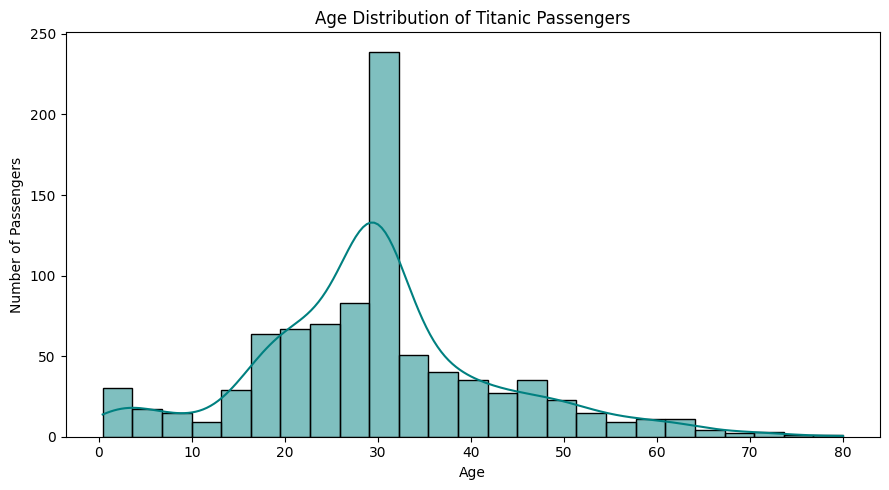

In [6]:

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Age",
    bins=25,
    kde=True,
    color="teal"
)

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.tight_layout()
plt.show()


What this tells you: How passenger ages were distributed and which age ranges were most common. Remember that missing ages were imputed with the mean, so the cleaned histogram includes estimated values.

# Cell 7 — Correlation heatmap

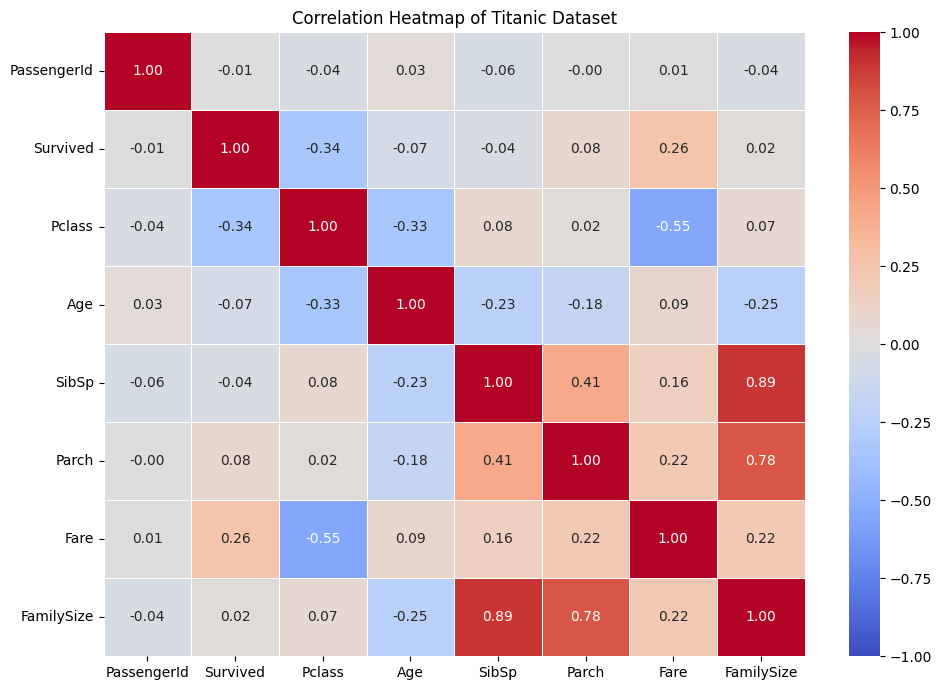

In [7]:

# Select numeric columns for correlation analysis
numeric_df = df.select_dtypes(include="number")

correlation = numeric_df.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Titanic Dataset")
plt.tight_layout()
plt.show()


What this tells you: The strength and direction of relationships between numeric variables. Correlation ranges from -1 to +1. A positive value indicates variables tend to increase together; a negative value indicates an inverse relationship. Correlation does not establish causation.

# Cell 8 — Print a final summary

In [8]:

print("=" * 50)
print("TITANIC DATASET - TASK 3 SUMMARY")
print("=" * 50)

print("\nOverall survival rate:")
print(f"{df['Survived'].mean() * 100:.2f}%")

print("\nSurvival rate by age group (%):")
print(age_survival)

print("\nSurvival rate by embarkation port (%):")
print(port_survival)

print("\nSurvival rate by family size (%):")
print(family_survival["Survival Rate (%)"])

print("\nTotal passengers:", len(df))
print("Missing Age values:", df["Age"].isnull().sum())
print("Cabin column present:", "Cabin" in df.columns)


TITANIC DATASET - TASK 3 SUMMARY

Overall survival rate:
38.38%

Survival rate by age group (%):
AgeGroup
Child          57.97
Teenager       42.86
Young Adult    35.33
Adult          40.00
Senior         22.73
Name: Survived, dtype: float64

Survival rate by embarkation port (%):
Embarked
Cherbourg      55.36
Queenstown     38.96
Southampton    33.90
Name: Survived, dtype: float64

Survival rate by family size (%):
FamilySize
0     30.35
1     55.28
2     57.84
3     72.41
4     20.00
5     13.64
6     33.33
7      0.00
10     0.00
Name: Survival Rate (%), dtype: float64

Total passengers: 891
Missing Age values: 0
Cabin column present: False


Conclusion

In this task, I performed Exploratory Data Analysis (EDA) on the Titanic dataset using Python,
Pandas, Matplotlib, and Seaborn.

First, I cleaned the dataset by replacing missing Age values with the mean and removing the
Cabin column. I then created age groups and calculated family size using SibSp + Parch.

Next, I analyzed survival rates by age group, embarkation port, and family size. I created an age
distribution histogram, a correlation heatmap, and a bar plot showing survival rates by family
size.

These analyses helped me understand patterns in passenger survival and practice data
cleaning, grouping, statistical analysis, and data visualization.

 Key findings : Add the highest and lowest survival rates from your actual outputs here,
along with one or two observations from your charts.